In [1]:
# 0. Imports
import pandas as pd, glob
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, ConfusionMatrixDisplay


In [2]:
# 1. Load data
df = pd.concat([pd.read_csv(f, encoding="latin-1", on_bad_lines="skip") for f in glob.glob("data/*.csv")])
df.head()

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,PPA,SKBH,SKBD,SKBA,PPCH,PPCD,PPCA,SKBCH,SKBCD,SKBCA
0,E0,13/08/16,Burnley,Swansea,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,13/08/16,Crystal Palace,West Brom,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,13/08/16,Everton,Tottenham,1,1,D,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,13/08/16,Hull,Leicester,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,13/08/16,Man City,Sunderland,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
# 2. Clean dates and sort matches
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df.sort_values("Date").reset_index(drop=True)
df.head()

C:\Users\vikra\AppData\Local\Temp\ipykernel_4552\1909126261.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,PPA,SKBH,SKBD,SKBA,PPCH,PPCD,PPCA,SKBCH,SKBCD,SKBCA
0,E0,2016-08-13,Burnley,Swansea,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,2016-08-13,Crystal Palace,West Brom,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,2016-08-13,Everton,Tottenham,1,1,D,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,2016-08-13,Hull,Leicester,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,2016-08-13,Man City,Sunderland,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# 3. Elo: expected result formula
def elo_expected(r_home, r_away, home_adv=60):
    return 1/(1+10**((r_away - (r_home + home_adv))/400))

In [5]:
# 4. Elo: compute ratings (K=40)
def compute_elo(data, K=40, home_adv=60, carry=1.0, mov=False):
    ratings, home_elo, away_elo = {}, [], []
    season = None
    for _, row in data.iterrows():
        d = row["Date"]
        s = d.year if d.month >= 8 else d.year - 1
        if s != season:
            ratings = {t: 1500 + carry * (r - 1500) for t, r in ratings.items()}
            season = s
        h, a = row["HomeTeam"], row["AwayTeam"]
        rh, ra = ratings.get(h, 1500), ratings.get(a,1500)
        home_elo.append(rh)
        away_elo.append(ra)
        actual = {"H": 1, "D": 0.5, "A": 0}[row["FTR"]]
        mult = 1
        if mov: 
            gd = abs(row["FTHG"] - row["FTAG"])
            mult = 1 if gd <= 1 else 1.5 if gd == 2 else (11 + gd) / 8
        change = K * mult * (actual - elo_expected(rh, ra, home_adv))
        ratings[h], ratings[a] = rh + change, ra - change
    return home_elo, away_elo, ratings

df["home_elo"], df["away_elo"], ratings = compute_elo(df)

C:\Users\vikra\AppData\Local\Temp\ipykernel_4552\1714535480.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["home_elo"], df["away_elo"], ratings = compute_elo(df)
C:\Users\vikra\AppData\Local\Temp\ipykernel_4552\1714535480.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["home_elo"], df["away_elo"], ratings = compute_elo(df)


In [6]:
# 5. Elo: top 6 teams
sorted(ratings.items(), key=lambda x: x[1], reverse=True)[:6]

[('Man City', 1821.5400439176),
 ('Arsenal', 1814.2873557915814),
 ('Man United', 1675.96224452354),
 ('Liverpool', 1655.0215501482749),
 ('Brighton', 1645.172488323826),
 ('Brentford', 1638.3915144003952)]

In [7]:
# 6. Build team rows (one per team per match)
home = pd.DataFrame({"Date": df["Date"], "Team": df["HomeTeam"], "GF": 
df["FTHG"], "GA": df["FTAG"], "Shots": df["HS"], "SOT": df["HST"], "Result": df["FTR"].map({"H": 3, "D": 1, "A": 0})})
away = pd.DataFrame({"Date": df["Date"], "Team": df["AwayTeam"], "GF": df["FTAG"], "GA": df["FTHG"], "Shots": df["AS"], "SOT": df["AST"], "Result": df["FTR"].map({"A": 3, "D": 1, "H": 0})})
teams = pd.concat([home, away]).sort_values("Date").reset_index(drop=True)
teams.head()

,Date,Team,GF,GA,Shots,SOT,Result
0,2016-08-13,Burnley,0,1,10,3,0
1,2016-08-13,Tottenham,1,1,13,4,1
2,2016-08-13,Leicester,1,2,18,5,0
3,2016-08-13,Sunderland,1,2,7,3,0
4,2016-08-13,Stoke,1,1,12,1,1


In [8]:
# 7. Rolling form (last 5 & 10)
for col in ["GF", "GA", "Shots", "SOT", "Result"]:
    for n in [5, 10]:
        teams[f"{col}_last{n}"] = teams.groupby("Team")[col].transform(lambda s: s.shift(1).rolling(n).mean())
teams.head(10)

,Date,Team,GF,GA,Shots,SOT,Result,GF_last5,GF_last10,GA_last5,GA_last10,Shots_last5,Shots_last10,SOT_last5,SOT_last10,Result_last5,Result_last10
0,2016-08-13,Burnley,0,1,10,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2016-08-13,Tottenham,1,1,13,4,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2016-08-13,Leicester,1,2,18,5,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2016-08-13,Sunderland,1,2,7,3,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2016-08-13,Stoke,1,1,12,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2016-08-13,Watford,1,1,5,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2016-08-13,West Brom,1,0,13,3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2016-08-13,Swansea,1,0,17,9,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2016-08-13,Southampton,1,1,24,6,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2016-08-13,Middlesbrough,1,1,12,2,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
# 8. Form check: Arsenal
teams[teams["Team"] == "Arsenal"].tail(10)

,Date,Team,GF,GA,Shots,SOT,Result,GF_last5,GF_last10,GA_last5,GA_last10,Shots_last5,Shots_last10,SOT_last5,SOT_last10,Result_last5,Result_last10
7513,2026-04-25,Arsenal,1,0,11,4,3,1.4,2.1,1.0,0.9,13.6,13.5,4.0,4.6,1.8,2.0
7523,2026-05-02,Arsenal,3,0,18,9,3,1.2,1.8,0.8,0.9,13.4,13.2,3.8,4.2,1.8,2.0
7550,2026-05-10,Arsenal,1,0,15,4,3,1.6,1.8,0.8,0.9,15.6,13.4,5.2,4.6,1.8,2.0
7574,2026-05-18,Arsenal,1,0,13,3,3,1.4,1.8,0.8,0.8,13.6,14.2,4.6,4.8,1.8,2.2
7584,2026-05-24,Arsenal,2,1,17,7,3,1.4,1.7,0.4,0.6,13.2,14.5,4.6,4.7,2.4,2.4
7600,2026-08-21,Arsenal,3,0,20,6,3,1.6,1.5,0.2,0.6,14.8,14.2,5.4,4.7,3.0,2.4
7638,2026-08-31,Arsenal,1,0,7,2,3,2.0,1.6,0.2,0.5,16.6,15.0,5.8,4.8,3.0,2.4
7659,2026-09-06,Arsenal,2,1,16,9,3,1.6,1.6,0.2,0.5,14.4,15.0,4.4,4.8,3.0,2.4
7664,2026-09-12,Arsenal,2,0,11,5,3,1.8,1.6,0.4,0.6,14.6,14.1,5.4,5.0,3.0,2.4
7684,2026-09-19,Arsenal,0,3,11,2,0,2.0,1.7,0.4,0.4,14.2,13.7,5.8,5.2,3.0,2.7


In [10]:
# 9. Merge features onto matches
features = [c for c in teams.columns if "_last" in c]
home_form = teams[["Date", "Team"] + features].rename(columns={f: "home_" + f for f in features})
away_form = teams[["Date", "Team"] + features].rename(columns={f: "away_" + f for f in features})
matches = df[["Date", "HomeTeam", "AwayTeam", "FTR", "home_elo", "away_elo"]]
matches = matches.merge(home_form, left_on=["Date", "HomeTeam"], right_on=["Date", "Team"]).drop(columns="Team")
matches = matches.merge(away_form, left_on=["Date", "AwayTeam"], right_on=["Date", "Team"]).drop(columns="Team")
matches = matches.dropna()
matches.head()

,Date,HomeTeam,AwayTeam,FTR,home_elo,away_elo,home_GF_last5,home_GF_last10,home_GA_last5,home_GA_last10,...,away_GF_last5,away_GF_last10,away_GA_last5,away_GA_last10,away_Shots_last5,away_Shots_last10,away_SOT_last5,away_SOT_last10,away_Result_last5,away_Result_last10
100,2016-11-05,Bournemouth,Sunderland,A,1491.082077,1373.466930,1.8,1.2,1.0,1.4,...,0.8,0.7,2.2,2.0,8.4,8.9,2.0,2.4,0.2,0.2
101,2016-11-05,Burnley,Crystal Palace,H,1476.982429,1459.776950,1.0,0.8,1.0,1.3,...,1.4,1.4,2.2,1.6,14.4,14.6,4.4,4.5,0.8,1.1
102,2016-11-05,Chelsea,Everton,H,1584.339096,1538.456536,2.2,2.1,0.6,0.9,...,1.0,1.5,1.0,0.8,13.2,14.3,4.2,5.8,1.0,1.8
103,2016-11-05,Man City,Middlesbrough,D,1592.187855,1471.120258,1.8,2.4,1.0,0.9,...,0.8,0.9,0.8,1.1,9.2,9.2,3.0,2.6,1.0,1.0
104,2016-11-05,West Ham,Stoke,D,1451.187891,1491.779614,0.6,1.0,1.2,1.9,...,1.8,1.2,0.6,1.7,13.2,12.0,4.8,3.5,2.2,1.2


In [11]:
# 10. Imports and train/test split
X_cols = ["home_elo", "away_elo"]
train = matches[matches["Date"] < "2025-08-01"]
test = matches[(matches["Date"] >= "2025-08-01") & (matches["Date"] < "2026-08-01")]
X_train, y_train = train[X_cols], train["FTR"]
X_test, y_test = test[X_cols], test["FTR"]

In [12]:
# 11. Validation: evaluate() function
def evaluate(cols, data=None):
    if data is None:
        data = matches
    fit_part = data[data["Date"] < "2024-08-01"]
    val = data[(data["Date"] >= "2024-08-01") & (data["Date"] < "2025-08-01")]
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    m.fit(fit_part[cols], fit_part["FTR"])
    acc = accuracy_score(val["FTR"], m.predict(val[cols]))
    ll = log_loss(val["FTR"], m.predict_proba(val[cols]), labels=m.classes_)
    return round(acc, 3), round(ll, 4)

I compared the model with multiple and different features and in a 5-10 game margin. Out of everything, using only Elo proved to give the best result which is why I'm using Elo only.I tested it with the 24-25 dataframe. 
Update: This test was done with K=20. Now using K=40.

In [13]:
# 12. Validation: compare feature sets
elo = ["home_elo", "away_elo"]
def cols(stats, n):
    return [f"{s}_{c}_last{n}" for s in ["home", "away"] for c in stats]

options = {
    "current": elo + cols(["GF", "GA", "Shots", "Result"], 5), "+ SOT": elo + cols(["GF", "GA", "Shots", "SOT", "Result"], 5), "last 10": elo + cols(["GF", "GA", "Shots", "SOT", "Result"], 10), "5 and 10": elo + cols(["GF", "GA", "Shots", "SOT", "Result"], 5) + cols(["GF", "GA", "Shots", "SOT", "Result"], 10), "Elo only": elo,
}
for name, c in options.items():
    print(name, evaluate(c))

current (0.541, 0.9856)
+ SOT (0.546, 0.9856)
last 10 (0.519, 0.9963)
5 and 10 (0.524, 1.0024)
Elo only (0.538, 0.9857)


K = 40 gives the best log loss. Home advantage is basically pointless. Pulling rating towards 1500 and margin of victory both made things worse. final tuning for elo is K = 40 and home_adv = 60

In [14]:
# 13. Validation: Elo grid (K and home advantage)
def evaluate_elo(**params):
    h, a, _ = compute_elo(df, **params)
    elo_df = df[["Date", "HomeTeam", "AwayTeam"]].assign(home_elo=h, away_elo=a)
    data = matches.drop(columns=["home_elo", "away_elo"]).merge(elo_df, on=["Date", "HomeTeam", "AwayTeam"])
    return evaluate(["home_elo", "away_elo"], data)

for K in [10, 20, 30, 40]:
    for ha in [40, 60, 80, 100]:
        print(K, ha, evaluate_elo(K=K, home_adv=ha))

10 40 (0.511, 1.0151)
10 60 (0.514, 1.0156)
10 80 (0.516, 1.0163)
10 100 (0.516, 1.0173)
20 40 (0.532, 0.9928)
20 60 (0.532, 0.993)
20 80 (0.532, 0.9933)
20 100 (0.532, 0.9938)
30 40 (0.543, 0.9867)
30 60 (0.541, 0.9867)
30 80 (0.541, 0.9868)
30 100 (0.538, 0.9869)
40 40 (0.538, 0.9859)
40 60 (0.538, 0.9857)
40 80 (0.538, 0.9855)
40 100 (0.541, 0.9854)


In [15]:
# 14. Validation: higher K values
for K in [40, 50, 60, 80]:
    print(K, evaluate_elo(K=K, home_adv=60))

40 (0.538, 0.9857)
50 (0.535, 0.9868)
60 (0.538, 0.9887)
80 (0.532, 0.9936)


In [16]:
# 15. Validation: season carry-over and margin of victory
best_K, best_ha = 40, 60
for carry in [1.0, 0.9, 0.8, 0.7]:
    for mov in [False, True]:
        print(carry, mov, evaluate_elo(K=best_K, home_adv=best_ha, carry=carry, mov=mov))

1.0 False (0.538, 0.9857)
1.0 True (0.532, 0.9898)
0.9 False (0.538, 0.986)
0.9 True (0.532, 0.9901)
0.8 False (0.538, 0.9867)
0.8 True (0.535, 0.9909)
0.7 False (0.535, 0.9879)
0.7 True (0.535, 0.992)


In [17]:
# 16. Model: logistic regression (test accuracy)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Model accuracy:", accuracy_score(y_test, pred))
print("Always-home baseline:", (y_test == "H").mean())

Model accuracy: 0.5
Always-home baseline: 0.4263157894736842


In [18]:
# 17. Model: random forest (comparison)
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)
print("Random forest accuracy:", accuracy_score(y_test, rf.predict(X_test)))

Random forest accuracy: 0.48157894736842105


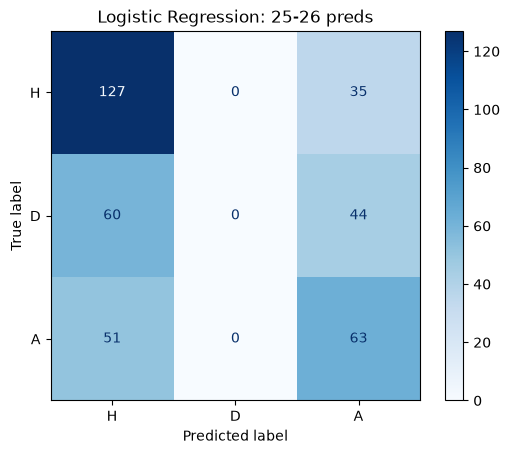

In [19]:
# 18. Confusion matrix
labels = ["H", "D", "A"]
cm = confusion_matrix(y_test, pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Logistic Regression: 25-26 preds")
plt.show()

In [20]:
# 19. Validation: draw margin tuning
fit_part = train[train["Date"] < "2024-08-01"]
val = train[train["Date"] >= "2024-08-01"]
tmp = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
tmp.fit(fit_part[X_cols], fit_part["FTR"])
val_probs = pd.DataFrame(tmp.predict_proba(val[X_cols]), columns=tmp.classes_, index=val.index)
for m in [0, 0.05, 0.10, 0.15, 0.20]:
    close = (val_probs["H"] - val_probs["A"]).abs() < m
    picks = val_probs.idxmax(axis=1).where(~close, "D")
    print(m, round(accuracy_score(val["FTR"], picks), 3), (picks == "D").sum(), "draws")

0 0.538 0 draws
0.05 0.519 30 draws
0.1 0.522 61 draws
0.15 0.495 87 draws
0.2 0.481 109 draws


The model wasn't predicting any draws. I tested calling a draw when the two teams' win probability was withn a margin. everything above 0 reduced accuracy and the draw calls were very few to the point of being redundant. this made me keep best_m as 0.

In [21]:
# 20. Apply draw margin to test season
best_m = 0.0
test_probs = pd.DataFrame(model.predict_proba(X_test), columns=model.classes_, index=X_test.index)
close = (test_probs["H"] - test_probs["A"]).abs() < best_m
final_picks = test_probs.idxmax(axis=1).where(~close, "D")
print("Accuracy with draw rule:", accuracy_score(y_test, final_picks))
print("Draws predicted:", (final_picks == "D").sum())

Accuracy with draw rule: 0.5
Draws predicted: 0


In [22]:
# 21. Test predictions table
results = test[["Date", "HomeTeam", "AwayTeam", "FTR"]].copy()
results["Pick"] = final_picks
results[["P(H)", "P(D)", "P(A)"]] = test_probs[["H", "D", "A"]].round(2)
results.tail(10)

,Date,HomeTeam,AwayTeam,FTR,Pick,P(H),P(D),P(A)
3790,2026-05-24,Sunderland,Chelsea,H,H,0.41,0.25,0.34
3791,2026-05-24,Nott'm Forest,Bournemouth,D,A,0.33,0.24,0.43
3792,2026-05-24,Man City,Aston Villa,A,H,0.69,0.19,0.13
3793,2026-05-24,Liverpool,Brentford,D,H,0.51,0.24,0.26
3794,2026-05-24,West Ham,Leeds,H,A,0.35,0.25,0.40
3795,2026-05-24,Crystal Palace,Arsenal,A,A,0.19,0.21,0.60
3796,2026-05-24,Fulham,Newcastle,H,H,0.42,0.25,0.33
3797,2026-05-24,Tottenham,Everton,H,A,0.33,0.25,0.42
3798,2026-05-24,Burnley,Wolves,D,A,0.36,0.27,0.37
3799,2026-05-24,Brighton,Man United,A,A,0.35,0.24,0.41


In [23]:
# 22. Draw calls check
draw_calls = final_picks == "D"
print("Draw calls:", draw_calls.sum())
print("Correct draw calls:", (y_test[draw_calls] == "D").sum())

Draw calls: 0
Correct draw calls: 0


In [24]:
# 23. Bookmaker benchmark
season = df[(df["Date"] >= "2025-08-01") & (df["Date"] < "2026-08-01")]
fav = season[["B365H", "B365D", "B365A"]].idxmin(axis=1).str[-1]
print("Bookmaker favourite accuracy:", (fav == season["FTR"]).mean())
print("Matches:", len(season))

Bookmaker favourite accuracy: 0.48947368421052634
Matches: 380


In [25]:
# 24. Bookmaker vs log loss (2025-26)
imp = 1 / season[["B365A", "B365D", "B365H"]]
imp = imp.div(imp.sum(axis=1), axis=0)
print("Bookmaker log loss:", round(log_loss(season["FTR"], imp.values, labels=["A", "D", "H"]), 4))
print("Model log loss:", round(log_loss(y_test, model.predict_proba(X_test), labels=model.classes_), 4))

Bookmaker log loss: 1.0185
Model log loss: 1.041


In [26]:
# 25. Live: train final model on all matches
final_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
final_model.fit(matches[X_cols], matches["FTR"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['A','D','H']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](2,)","['home_elo','away_elo']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [27]:
# 26. Live: predict upcoming fixtures
fixtures = [
    ("Arsenal", "Leeds"),
    ("Aston Villa", "Brentford"),
    ("Ipswich", "Fulham"),
    ("Chelsea", "Bournemouth"),
    ("Sunderland", "Brighton"),
    ("Man United", "Tottenham"),
    ("Crystal Palace", "Nott'm Forest"),
    ("Hull", "Everton"),
    ("Liverpool", "Man City"),
    ("Coventry", "Newcastle"),
]
upcoming = pd.DataFrame([{"home_elo": ratings[h], "away_elo": ratings[a]} for h, a in fixtures])[X_cols]
probs = pd.DataFrame(final_model.predict_proba(upcoming), columns=final_model.classes_)
probs.insert(0, "Match", [f"{h} vs {a}" for h, a in fixtures])
probs["Pick"] = probs[["H", "D", "A"]].idxmax(axis=1)
probs.round(2)

,Match,A,D,H,Pick
0,Arsenal vs Leeds,0.12,0.19,0.69,H
1,Aston Villa vs Brentford,0.33,0.25,0.42,H
2,Ipswich vs Fulham,0.45,0.26,0.29,A
3,Chelsea vs Bournemouth,0.37,0.25,0.38,H
4,Sunderland vs Brighton,0.41,0.25,0.34,A
5,Man United vs Tottenham,0.12,0.20,0.68,H
6,Crystal Palace vs Nott'm Forest,0.34,0.26,0.40,H
7,Hull vs Everton,0.46,0.25,0.28,A
8,Liverpool vs Man City,0.49,0.23,0.27,A
9,Coventry vs Newcastle,0.43,0.26,0.31,A


In [29]:
# 27. Gameweek 6: predictions & results
gw6 = pd.DataFrame({
    "Match": ["Arsenal vs Leeds", "Aston Villa vs Brentford", "Ipswich vs Fulham", "Chelsea vs Bournemouth", "Sunderland vs Brighton", "Man United vs Tottenham", "Crystal Palace vs Nott'm Forest", "Hull vs Everton", "Liverpool vs Man City", "Coventry vs Newcastle"],
    "A": [0.12, 0.33, 0.45, 0.37, 0.41, 0.12, 0.34, 0.46, 0.49, 0.43],
    "D": [0.19, 0.25, 0.26, 0.25, 0.25, 0.20, 0.26, 0.25, 0.23, 0.26],
    "H": [0.69, 0.42, 0.29, 0.38, 0.34, 0.68, 0.40, 0.28, 0.27, 0.31],
    "Pick": ["H", "H", "A", "H", "A", "H", "H", "A", "A", "A"],
    "Actual": ["H", "D", "H", "H", "A", "D", "H", "D", "A", "H"],
})
gw6.to_csv("predictions/gw6.csv", index=False)